# Predicting assessment scores with strictly earlier score histories

This experiment compares course/background inputs with the same inputs plus prior
assessment scores. Each prediction is made **one day before the scheduled deadline**.
History comes only from the same student, module, and presentation. Student IDs are
grouping keys, never model inputs. Test students are absent from model fitting.

**Important availability limitation:** OULAD records submission dates and final scores,
but does not supply a grade-release timestamp in these files. We therefore cannot
certify real-world score availability. The main experiment assumes a score is available
28 days after the later of its deadline and submission. A predeclared 56-day sensitivity
experiment tests robustness. These are assumptions, not documented marking guarantees.
In deployment, replace this proxy with actual grade-release timestamps. A result here
must be described as leakage-controlled **under the stated availability assumption**.

Reference: [OULAD data descriptor, assessments and studentAssessment tables](https://pmc.ncbi.nlm.nih.gov/articles/PMC5704676/).


All comparison models below are fitted and evaluated on exactly the same eligible
rows and student partitions. Records with unknown deadlines are excluded because
their historical cutoffs cannot be established safely. The student holdout was
previously inspected during earlier experiments; this is a fixed comparative
experiment, not a new blind test or a future-course forecasting evaluation.


In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import xgboost

SEED = 42
DATA_DIR = Path('data') if Path('data/combinedfile_cleaned.csv').exists() else Path('notebook/data')
print({'python': platform.python_version(), 'pandas': pd.__version__,
       'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__})


{'python': '3.12.14', 'pandas': '3.0.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1'}


In [2]:
PRIMARY_LAG = 28
SENSITIVITY_LAG = 56
NOTABLE_REDUCTION = 0.10
BOOTSTRAP_REPLICATES = 1000

df = pd.read_csv(DATA_DIR / 'combinedfile_cleaned.csv')
assert df['score'].notna().all() and df['score'].between(0, 100).all()
assert not df.duplicated(['id_student', 'id_assessment']).any()
assert df[['id_student', 'code_module', 'code_presentation']].notna().all().all()
assert df['date_submitted'].notna().all()

# Retain the established reproducible student allocation on the full cleaned data.
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_full, test_full = next(outer.split(df, df.score, df.id_student))
inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)
train_rel, val_rel = next(inner.split(df.iloc[trainval_full],
    df.score.iloc[trainval_full], df.id_student.iloc[trainval_full]))
split_label = pd.Series(index=df.index, dtype='object')
split_label.iloc[trainval_full[train_rel]] = 'train'
split_label.iloc[trainval_full[val_rel]] = 'validation'
split_label.iloc[test_full] = 'test'
assert split_label.notna().all()
assert pd.DataFrame({'student': df.id_student, 'split': split_label}).groupby(
    'student')['split'].nunique().max() == 1

# Missing deadlines cannot be ordered safely; do not invent an exam date.
eligible = df['date'].notna()
frame = df.loc[eligible].copy()
frame['prediction_day'] = frame['date'] - 1
splits = {name: frame.index[split_label.loc[frame.index].eq(name)]
          for name in ['train', 'validation', 'test']}
assert all(len(idx) for idx in splits.values())
display(pd.DataFrame([
    {'split': name, 'rows': len(idx), 'students': frame.loc[idx, 'id_student'].nunique()}
    for name, idx in splits.items()]))
print(f'Excluded {int((~eligible).sum()):,} records with unknown deadlines; '
      f'retained {len(frame):,}, including first assessments with no history.')
print('Score-release assumptions and robustness criterion fixed before fitting.')


,split,rows,students
0,train,102339,13974
1,validation,32853,4658
2,test,33774,4659


Excluded 2,865 records with unknown deadlines; retained 168,966, including first assessments with no history.
Score-release assumptions and robustness criterion fixed before fitting.


## Build each history at its prediction cutoff

Do not merely sort by assessment ID and shift scores. IDs do not establish availability,
and a late submission may occur after the next assessment's prediction date. A source
score is usable only if `max(source deadline, source submission) + lag < prediction day`.
This excludes the target itself, same-cutoff events, later deadlines, and late scores.
Unknown-deadline records cannot supply history. Histories never cross course presentations.

Test students may supply their **own previously available** grades for later predictions.
This simulates sequential operation; no test labels fit model parameters, preprocessing,
or other students' histories. It does not simulate predicting every test assessment at
course start. Current/future scores and `final_result` never enter a target's inputs.


In [3]:
HISTORY_COLUMNS = ['prior_count', 'prior_mean', 'prior_std', 'prior_min', 'prior_max',
    'prior_latest_mean', 'prior_recent3_mean', 'prior_trend', 'days_since_latest_score']
GROUP_KEYS = ['id_student', 'code_module', 'code_presentation']

def history_features(data, lag_days, target_index=None):
    targets = data if target_index is None else data.loc[target_index]
    # Accumulate in NumPy arrays rather than repeated DataFrame row assignments.
    output = np.full((len(targets), len(HISTORY_COLUMNS)), np.nan)
    output[:, 0] = 0.0
    audit_output = np.full((len(targets), 2), np.nan)
    positions = dict(zip(targets.index, range(len(targets))))
    source_groups = {key: group for key, group in data.groupby(GROUP_KEYS, sort=False)}
    for key, group in targets.groupby(GROUP_KEYS, sort=False):
        sources = source_groups[key].copy()
        sources['available_day'] = np.maximum(sources['date'], sources['date_submitted']) + lag_days
        sources = sources.sort_values(['available_day', 'date', 'id_assessment'])
        availability = sources['available_day'].to_numpy()
        scores = sources['score'].to_numpy()
        deadlines = sources['date'].to_numpy()
        assessment_ids = sources['id_assessment'].to_numpy()
        for row in group.itertuples():
            stop = np.searchsorted(availability, row.prediction_day, side='left')
            if not stop:
                continue
            values = scores[:stop]
            assert (availability[:stop] < row.prediction_day).all()
            assert (deadlines[:stop] < row.prediction_day).all()
            assert row.id_assessment not in assessment_ids[:stop]
            latest_day = availability[stop - 1]
            latest = values[availability[:stop] == latest_day]
            # A tie in release-proxy day is summarized as a batch, not an invented order.
            earlier = values[availability[:stop] < latest_day]
            previous_day_values = (earlier[availability[:len(earlier)] ==
                availability[len(earlier) - 1]] if len(earlier) else np.array([]))
            position = positions[row.Index]
            output[position] = [stop, values.mean(), values.std(ddof=0),
                values.min(), values.max(), latest.mean(), values[-3:].mean(),
                latest.mean() - previous_day_values.mean() if len(previous_day_values) else 0.0,
                row.prediction_day - latest_day]
            audit_output[position] = [latest_day, deadlines[:stop].max()]
    features = pd.DataFrame(output, index=targets.index, columns=HISTORY_COLUMNS)
    audit = pd.DataFrame(audit_output, index=targets.index,
        columns=['latest_source_available_day', 'latest_source_deadline'])
    used = features['prior_count'].gt(0)
    assert audit.loc[used, 'latest_source_available_day'].lt(targets.loc[used, 'prediction_day']).all()
    assert audit.loc[used, 'latest_source_deadline'].lt(targets.loc[used, 'prediction_day']).all()
    return features, audit

history_by_lag, audit_by_lag = {}, {}
for lag in [PRIMARY_LAG, SENSITIVITY_LAG]:
    history_by_lag[lag], audit_by_lag[lag] = history_features(frame, lag)
    print(f'{lag}-day lag: {history_by_lag[lag].prior_count.gt(0).mean():.1%} of targets have history')
assert (history_by_lag[SENSITIVITY_LAG].prior_count <= history_by_lag[PRIMARY_LAG].prior_count).all()
display(pd.DataFrame([
    {'lag_days': lag, 'split': name, 'rows': len(idx),
     'with_history': int(history.loc[idx, 'prior_count'].gt(0).sum()),
     'history_coverage_pct': 100 * history.loc[idx, 'prior_count'].gt(0).mean()}
    for lag, history in history_by_lag.items() for name, idx in splits.items()]))


28-day lag: 74.4% of targets have history


56-day lag: 65.8% of targets have history


,lag_days,split,rows,with_history,history_coverage_pct
0,28,train,102339,76238,74.495549
1,28,validation,32853,24329,74.054120
2,28,test,33774,25109,74.344170
3,56,train,102339,67498,65.955305
4,56,validation,32853,21462,65.327367
5,56,test,33774,22188,65.695505


## Leakage checks by changing labels

These checks validate behavior, not just sorting: changing a target or any score not yet
available at its cutoff must not change its features; changing another student's labels
must not affect its history. Changing a genuinely available prior score must affect a
later history. This cannot validate the unobserved real grade-release timestamp.


In [4]:
# Choose a rich history group so checks exercise actual historical dependencies.
example_key = frame.groupby(GROUP_KEYS).size().idxmax()
example = frame.set_index(GROUP_KEYS).loc[[example_key]].reset_index()
example['prediction_day'] = example['date'] - 1
example.index = np.arange(len(example))
example_features, _ = history_features(example, PRIMARY_LAG)
tested = 0
for target in example.itertuples():
    changed = example.copy()
    source_availability = np.maximum(changed['date'], changed['date_submitted']) + PRIMARY_LAG
    forbidden = source_availability.ge(target.prediction_day)
    changed.loc[forbidden, 'score'] = 100 - changed.loc[forbidden, 'score']
    changed_features, _ = history_features(changed, PRIMARY_LAG, [target.Index])
    pd.testing.assert_series_equal(example_features.loc[target.Index],
        changed_features.loc[target.Index], check_names=False)
    tested += 1

later_idx = example_features['prior_count'].idxmax()
assert example_features.loc[later_idx, 'prior_count'] > 0
changed = example.copy()
cutoff = changed.loc[later_idx, 'prediction_day']
available = np.maximum(changed['date'], changed['date_submitted']) + PRIMARY_LAG < cutoff
changed.loc[available, 'score'] += 1
changed_features, _ = history_features(changed, PRIMARY_LAG, [later_idx])
assert np.isclose(changed_features.loc[later_idx, 'prior_mean'],
                  example_features.loc[later_idx, 'prior_mean'] + 1)

other = example.copy()
other['id_student'] = -999
other['score'] = 100 - other['score']
combined = pd.concat([example, other], ignore_index=True)
combined_features, _ = history_features(combined, PRIMARY_LAG, example.index)
pd.testing.assert_frame_equal(example_features, combined_features)
print(f'Passed current/future-label invariance for {tested} targets, prior-score sensitivity, '
      'student isolation, deadline ordering, and availability checks.')


Passed current/future-label invariance for 14 targets, prior-score sensitivity, student isolation, deadline ordering, and availability checks.


## Hyperparameter tuning with training-only preprocessing

All five algorithms are tuned separately for context and 28-day history features.
The deterministic search includes every original recipe. Linear Regression searches
the intercept; KNN searches neighbor count and distance weighting; Decision Tree searches
depth and leaf size. Random Forest and XGBoost each add six seeded random configurations
over the explicit spaces below. The complete trial table records parameters and errors.

Preprocessing is fitted only on training students and cached within each feature set.
Selection uses the established student-disjoint validation RMSE, with no test inputs
or test metrics supplied to the search. This is a bounded holdout search, not an exhaustive
optimization or cross-validation estimate. The previously inspected test remains retrospective.
The 56-day sensitivity experiment reuses the selected 28-day recipe without tuning.


In [5]:
excluded = ['score', 'id_assessment', 'id_student', 'date_submitted', 'date',
            'prediction_day', 'final_result']
X_context = frame.drop(columns=excluded)
y = frame['score']
X_history = {lag: pd.concat([X_context, hist], axis=1)
             for lag, hist in history_by_lag.items()}
assert not set(excluded) & set(X_context.columns)
assert all(not set(excluded) & set(x.columns) for x in X_history.values())

def pipeline_for(X, estimator):
    numeric = X.select_dtypes(include='number').columns.tolist()
    categorical = X.select_dtypes(exclude='number').columns.tolist()
    preprocessor = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('scaler', StandardScaler())]), numeric),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)])
    return Pipeline([('preprocessor', preprocessor), ('model', clone(estimator))])

class ContextRule(RegressorMixin, BaseEstimator):
    def __init__(self, statistic='mean', history_column=None):
        self.statistic = statistic
        self.history_column = history_column

    def fit(self, X, y):
        keys = ['code_module', 'assessment_type']
        data = X[keys].copy()
        data['_target'] = np.asarray(y)
        self.lookup_ = data.groupby(keys)['_target'].agg(self.statistic)
        self.fallback_ = float(getattr(data['_target'], self.statistic)())
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_frame(X[['code_module', 'assessment_type']])
        fallback = self.lookup_.reindex(keys).fillna(self.fallback_).to_numpy()
        if self.history_column is None:
            return fallback
        observed = X[self.history_column].to_numpy()
        return np.where(np.isfinite(observed), observed, fallback)

def metrics(actual, predicted):
    return {'R2': r2_score(actual, predicted),
            'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
            'MAE': mean_absolute_error(actual, predicted)}

"""Deterministic bounded validation search; test rows are never passed to search."""
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor


def make_estimator(name, params):
    classes = {'Linear Regression': LinearRegression,
               'K-Neighbors Regressor': KNeighborsRegressor,
               'Decision Tree': DecisionTreeRegressor,
               'Random Forest': RandomForestRegressor, 'XGBoost': XGBRegressor}
    return classes[name](**params)


def search_specs(seed=42):
    """Include each original recipe, plus fixed grid/random search candidates."""
    originals = {
        'Linear Regression': {},
        'K-Neighbors Regressor': {'n_neighbors': 25, 'n_jobs': 4},
        'Decision Tree': {'max_depth': 12, 'min_samples_leaf': 20, 'random_state': seed},
        'Random Forest': {'n_estimators': 150, 'max_depth': 16,
            'min_samples_leaf': 10, 'max_features': .8, 'random_state': seed, 'n_jobs': 4},
        'XGBoost': {'n_estimators': 300, 'max_depth': 4, 'learning_rate': .05,
            'subsample': .8, 'colsample_bytree': .8, 'objective': 'reg:squarederror',
            'tree_method': 'hist', 'random_state': seed, 'n_jobs': 4},
    }
    spaces = {
        'Linear Regression': {'fit_intercept': [True, False]},
        'K-Neighbors Regressor': {'n_neighbors': [15, 50], 'weights': ['uniform', 'distance']},
        'Decision Tree': {'max_depth': [8, 16, None], 'min_samples_leaf': [10, 40]},
        'Random Forest': {'n_estimators': [150, 250], 'max_depth': [12, 20, None],
            'min_samples_leaf': [3, 10, 20], 'max_features': [.6, 1.]},
        'XGBoost': {'n_estimators': [300, 600], 'max_depth': [3, 5, 7],
            'learning_rate': [.03, .07], 'min_child_weight': [1, 10],
            'reg_lambda': [1., 10.], 'subsample': [.8, 1.], 'colsample_bytree': [.8, 1.]},
    }
    output = {}
    for name, base in originals.items():
        sampled = (ParameterSampler(spaces[name], n_iter=6, random_state=seed)
                   if name in ['Random Forest', 'XGBoost'] else ParameterGrid(spaces[name]))
        recipes = [base] + [{**base, **p} for p in sampled]
        output[name] = list({json.dumps(p, sort_keys=True): p for p in recipes}.values())
    return output


def tune_candidates(X, y, train_idx, val_idx, preprocessor, label='', seed=42):
    """Cache preprocessing fitted on training students only, then rank by validation RMSE.

    Validation uses the established student-disjoint holdout, not row-wise CV.
    Each algorithm retains its lowest-RMSE recipe; insertion order breaks ties.
    """
    assert set(train_idx).isdisjoint(val_idx)
    fitted = clone(preprocessor)
    train = fitted.fit_transform(X.loc[train_idx], y.loc[train_idx])
    validation = fitted.transform(X.loc[val_idx])
    candidates, rows = {}, []
    for name, recipes in search_specs(seed).items():
        best_rmse = np.inf
        for trial, params in enumerate(recipes):
            estimator = make_estimator(name, params)
            estimator.fit(train, y.loc[train_idx])
            pred = estimator.predict(validation)
            rmse = float(np.sqrt(mean_squared_error(y.loc[val_idx], pred)))
            rows.append({'Feature set': label, 'Model': name, 'Trial': trial,
                         'Original recipe': trial == 0, 'Parameters': params,
                         'Validation RMSE': rmse,
                         'Validation MAE': float(mean_absolute_error(y.loc[val_idx], pred)),
                         'Validation R2': float(r2_score(y.loc[val_idx], pred))})
            print(f'{label}: {name} {trial + 1}/{len(recipes)} RMSE={rmse:.5f}', flush=True)
            if rmse < best_rmse:
                best_rmse = rmse
                candidates[name] = Pipeline([('preprocessor', fitted), ('model', estimator)])
    return candidates, pd.DataFrame(rows)


context_tuned, context_trials = tune_candidates(X_context, y, splits['train'],
    splits['validation'], pipeline_for(X_context, LinearRegression()).named_steps['preprocessor'],
    'Context', SEED)
history_tuned, history_trials = tune_candidates(X_history[PRIMARY_LAG], y, splits['train'],
    splits['validation'], pipeline_for(X_history[PRIMARY_LAG], LinearRegression()).named_steps['preprocessor'],
    'History 28d', SEED)
tuning_trials = pd.concat([context_trials, history_trials], ignore_index=True)
display(tuning_trials)
context_candidates = {
    'Global mean': DummyRegressor(strategy='mean'),
    'Global median': DummyRegressor(strategy='median'),
    'Module/type mean': ContextRule('mean'),
    'Module/type median': ContextRule('median'),
    **context_tuned,
}
history_candidates = {
    'Prior mean rule': ContextRule('mean', 'prior_mean'),
    'Latest score rule': ContextRule('mean', 'prior_latest_mean'),
    **history_tuned,
}

def evaluate_validation(candidates, X, label):
    rows = []
    for name, model in candidates.items():
        print(f'Fitting {label}: {name}', flush=True)
        if name not in context_tuned:  # tuned pipelines are already training-fitted
            model.fit(X.loc[splits['train']], y.loc[splits['train']])
        train = metrics(y.loc[splits['train']], model.predict(X.loc[splits['train']]))
        val = metrics(y.loc[splits['validation']], model.predict(X.loc[splits['validation']]))
        rows.append({'Model': name, **{f'Train {k}': v for k, v in train.items()},
                     **{f'Validation {k}': v for k, v in val.items()}})
    return pd.DataFrame(rows).set_index('Model').sort_values('Validation RMSE')

context_validation = evaluate_validation(context_candidates, X_context, 'context only')
history_validation = evaluate_validation(history_candidates, X_history[PRIMARY_LAG], 'history 28d')
display(context_validation)
display(history_validation)
context_name = context_validation.index[0]
history_name = history_validation.index[0]
print(f'Validation-selected context baseline: {context_name}; history candidate: {history_name}')

selected_parameters = {}
for label, name, candidates, trials in [
    ('context', context_name, context_candidates, context_trials),
    ('history', history_name, history_candidates, history_trials)]:
    selected = trials.loc[trials.Model.eq(name)].sort_values('Validation RMSE', kind='stable').iloc[0]
    selected_parameters[label] = {'name': name, 'params': selected['Parameters'],
                                  'validation_rmse': float(selected['Validation RMSE'])}
print('Frozen selected recipes:', selected_parameters)


Context: Linear Regression 1/3 RMSE=17.72697


Context: Linear Regression 2/3 RMSE=17.72697


Context: Linear Regression 3/3 RMSE=17.72697


Context: K-Neighbors Regressor 1/5 RMSE=17.77995


Context: K-Neighbors Regressor 2/5 RMSE=18.15055


Context: K-Neighbors Regressor 3/5 RMSE=19.09584


... (68 outputs left out)

Fitting history 28d: XGBoost


,Train R2,Train RMSE,Train MAE,Validation R2,Validation RMSE,Validation MAE
Model,,,,,,
XGBoost,0.197863,16.789456,12.923809,0.166869,17.050596,13.130029
Random Forest,0.264828,16.073369,12.264738,0.155971,17.161753,13.200586
Decision Tree,0.162928,17.151170,13.207978,0.138898,17.334458,13.354052
K-Neighbors Regressor,0.215916,16.599453,12.600995,0.122142,17.502292,13.401432
Module/type mean,0.112518,17.660058,13.636763,0.108342,17.639332,13.622145
Linear Regression,0.105397,17.730768,13.628806,0.099459,17.726972,13.641420
Module/type median,0.012347,18.630073,13.112909,0.017054,18.520287,13.012054
Global mean,0.000000,18.746163,14.480575,-0.000045,18.680679,14.442019
Global median,-0.046856,19.180324,14.183088,-0.044313,19.089664,14.123368


,Train R2,Train RMSE,Train MAE,Validation R2,Validation RMSE,Validation MAE
Model,,,,,,
XGBoost,0.429602,14.157988,10.423947,0.364006,14.897361,10.955180
Random Forest,0.455353,13.834701,10.070467,0.357093,14.978111,10.998418
K-Neighbors Regressor,0.367838,14.904814,10.965661,0.327752,15.316085,11.289294
Decision Tree,0.399087,14.531762,10.630097,0.312823,15.485213,11.405483
Linear Regression,0.247494,16.261757,12.199794,0.239815,16.287056,12.212535
Prior mean rule,0.068340,18.094277,13.312899,0.053071,18.177813,13.309984
Latest score rule,-0.105257,19.708071,14.315921,-0.123088,19.796565,14.364653


Validation-selected context baseline: XGBoost; history candidate: XGBoost
Frozen selected recipes: {'context': {'name': 'XGBoost', 'params': {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 4}, 'validation_rmse': 17.050595578158177}, 'history': {'name': 'XGBoost', 'params': {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 1.0, 'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 4, 'reg_lambda': 1.0, 'min_child_weight': 10}, 'validation_rmse': 14.897360932493086}}


## Predeclared sensitivity and robustness check

Do not choose a more flattering release-delay assumption after seeing test scores.
The 56-day run uses the already selected 28-day history estimator, without reselection.
"Notable" is fixed at **at least 10% lower RMSE and MAE** than the validation-selected
context-only reference, on both validation and test, under both delay assumptions.
For both delays, a paired **student-cluster bootstrap** must also give positive lower
95% bounds for test RMSE and MAE improvements. The bootstrap describes sampling
uncertainty for these fitted models; it is not proof of generalization or actual grade availability.

This threshold is retained as a conservative robustness check, not a rule for managing
project files. The context-only baseline remains available within this notebook for
comparison regardless of whether the check passes. Rerunning never deletes files.


In [6]:
sensitivity_model = clone(history_candidates[history_name])
sensitivity_model.fit(X_history[SENSITIVITY_LAG].loc[splits['train']], y.loc[splits['train']])
sensitivity_validation = metrics(y.loc[splits['validation']],
    sensitivity_model.predict(X_history[SENSITIVITY_LAG].loc[splits['validation']]))
context_val_metrics = {k: float(context_validation.loc[context_name, f'Validation {k}'])
                       for k in ['R2', 'RMSE', 'MAE']}
primary_val_metrics = {k: float(history_validation.loc[history_name, f'Validation {k}'])
                       for k in ['R2', 'RMSE', 'MAE']}
validation_comparison = pd.DataFrame([
    {'Model': f'Context: {context_name}', **context_val_metrics},
    {'Model': f'History {PRIMARY_LAG}d: {history_name}', **primary_val_metrics},
    {'Model': f'History {SENSITIVITY_LAG}d: {history_name}', **sensitivity_validation},
]).set_index('Model')
for metric in ['RMSE', 'MAE']:
    validation_comparison[f'{metric} reduction (%)'] = (
        1 - validation_comparison[metric] / context_val_metrics[metric]) * 100
display(validation_comparison)


,R2,RMSE,MAE,RMSE reduction (%),MAE reduction (%)
Model,,,,,
Context: XGBoost,0.166869,17.050596,13.130029,0.000000,0.000000
History 28d: XGBoost,0.364006,14.897361,10.955180,12.628501,16.563928
History 56d: XGBoost,0.319243,15.412704,11.479125,9.606068,12.573502


## Feature importance: what does the model rely on?

Permutation importance asks how much RMSE increases when an input is shuffled while
the fitted model stays fixed. A larger positive increase means this model relies more
on that input for this validation sample. This is not a percentage contribution or a
causal effect; importances do not sum to 100%. Zero or negative values can reflect
little contribution, correlated alternatives, or permutation noise.

Use the **training-fitted, validation-selected history candidate**, not the final model
that will be refitted on training + validation. Sample up to 500 validation students,
keeping all their eligible assessment records, with a fixed seed and five shuffle
repetitions. Test students are not used. The same validation data already helped select
the model, so these are exploratory diagnostics, not a new independent performance estimate.

The individual-input table operates before one-hot encoding, so all encoded levels
of a categorical input move together through the complete pipeline. Correlated history
statistics can substitute for each other and make their individual importances look
small. A second analysis therefore shuffles **all historical features together** and
**all contextual features together**, preserving relationships within each block.
Shuffling can still create implausible combinations across blocks; interpret the sizes
as model sensitivities, not effects of real interventions or the value of retraining
without a feature group. Such a retraining comparison would require a separate ablation study.

Error bars below show the standard deviation across shuffle repetitions, not confidence
intervals over students. Assessments are weighted equally; repeated records from a
student are not independent observations.

Method reference: [scikit-learn permutation importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html).


In [7]:
from sklearn.inspection import permutation_importance

IMPORTANCE_STUDENTS = 500
IMPORTANCE_REPEATS = 5
importance_rng = np.random.default_rng(SEED + 10)
validation_students = frame.loc[splits['validation'], 'id_student'].unique()
importance_students = importance_rng.choice(validation_students,
    size=min(IMPORTANCE_STUDENTS, len(validation_students)), replace=False)
importance_idx = splits['validation'][
    frame.loc[splits['validation'], 'id_student'].isin(importance_students).to_numpy()]
assert set(frame.loc[importance_idx, 'id_student']).isdisjoint(
    set(frame.loc[splits['train'], 'id_student']))
assert set(frame.loc[importance_idx, 'id_student']).isdisjoint(
    set(frame.loc[splits['test'], 'id_student']))

# history_candidates were fitted on training students in the candidate-comparison cell.
importance_model = history_candidates[history_name]
X_importance = X_history[PRIMARY_LAG].loc[importance_idx].copy()
y_importance = y.loc[importance_idx]
importance_baseline_rmse = metrics(y_importance, importance_model.predict(X_importance))['RMSE']
print(f'Model: {history_name}; validation students: {len(importance_students):,}; '
      f'assessments: {len(importance_idx):,}; baseline RMSE: {importance_baseline_rmse:.3f}')

permutation_result = permutation_importance(
    importance_model, X_importance, y_importance,
    scoring='neg_root_mean_squared_error', n_repeats=IMPORTANCE_REPEATS,
    random_state=SEED + 11, n_jobs=1)
# With negative RMSE scoring, score_before - score_after equals RMSE_after - RMSE_before.
feature_importance = pd.DataFrame({
    'Feature': X_importance.columns,
    'Input group': ['History' if name in HISTORY_COLUMNS else 'Context'
                    for name in X_importance.columns],
    'Mean RMSE increase': permutation_result.importances_mean,
    'Shuffle standard deviation': permutation_result.importances_std,
}).sort_values('Mean RMSE increase', ascending=False).reset_index(drop=True)
display(feature_importance)

importance_groups = {
    'All historical inputs': list(HISTORY_COLUMNS),
    'All contextual inputs': list(X_context.columns),
}
grouped_importance_rows = []
grouped_rng = np.random.default_rng(SEED + 12)
importance_row_orders = [grouped_rng.permutation(len(X_importance))
                         for _ in range(IMPORTANCE_REPEATS)]
for group_name, columns in importance_groups.items():
    increases = []
    for row_order in importance_row_orders:
        shuffled = X_importance.copy()
        shuffled.loc[:, columns] = X_importance.iloc[row_order][columns].to_numpy()
        shuffled_rmse = metrics(y_importance, importance_model.predict(shuffled))['RMSE']
        increases.append(shuffled_rmse - importance_baseline_rmse)
    grouped_importance_rows.append({'Feature group': group_name, 'Inputs': len(columns),
        'Mean RMSE increase': float(np.mean(increases)),
        'Shuffle standard deviation': float(np.std(increases, ddof=0))})
grouped_feature_importance = pd.DataFrame(grouped_importance_rows).sort_values(
    'Mean RMSE increase', ascending=False).reset_index(drop=True)
display(grouped_feature_importance)
assert np.isfinite(feature_importance['Mean RMSE increase']).all()
assert np.isfinite(grouped_feature_importance['Mean RMSE increase']).all()
pd.testing.assert_frame_equal(X_importance, X_history[PRIMARY_LAG].loc[importance_idx])


Model: XGBoost; validation students: 500; assessments: 3,547; baseline RMSE: 14.763


,Feature,Input group,Mean RMSE increase,Shuffle standard deviation
0,weight,Context,1.719179,0.061352
1,assessment_type,Context,1.152296,0.054844
2,prior_mean,History,0.992569,0.053163
3,code_module,Context,0.579522,0.037075
4,prior_recent3_mean,History,0.499387,0.044630
5,prior_latest_mean,History,0.385569,0.011061
6,prior_count,History,0.358506,0.024678
7,region,Context,0.087973,0.038194
8,prior_min,History,0.078449,0.020448
9,code_presentation,Context,0.068342,0.026703


,Feature group,Inputs,Mean RMSE increase,Shuffle standard deviation
0,All historical inputs,9,4.873718,0.077885
1,All contextual inputs,12,3.428618,0.131909


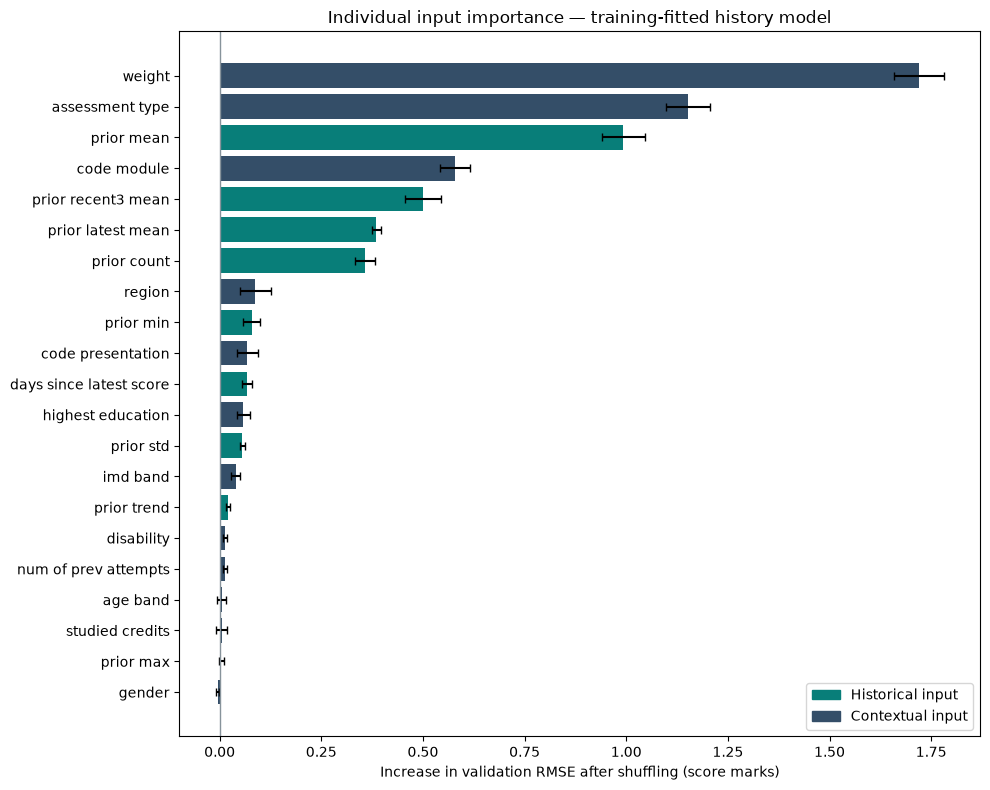

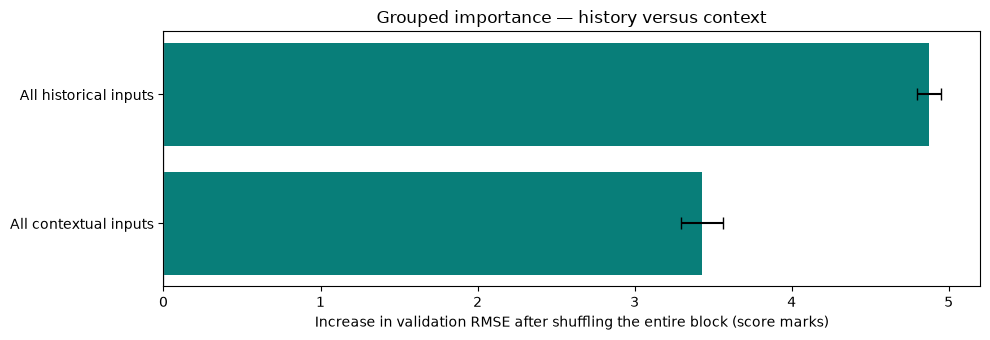

Largest individual permutation effects in this run:
weight: +1.719 RMSE marks (shuffle SD 0.061)
assessment_type: +1.152 RMSE marks (shuffle SD 0.055)
prior_mean: +0.993 RMSE marks (shuffle SD 0.053)
code_module: +0.580 RMSE marks (shuffle SD 0.037)
prior_recent3_mean: +0.499 RMSE marks (shuffle SD 0.045)
Read correlated historical statistics alongside the grouped comparison.
These diagnostics do not retrain the model, remove inputs, or change the test evaluation.


In [8]:
from matplotlib.patches import Patch

importance_plot = feature_importance.sort_values('Mean RMSE increase')
fig, ax = plt.subplots(figsize=(10, 8))
colors = importance_plot['Input group'].map({'History': '#087e79', 'Context': '#344e68'})
ax.barh(importance_plot['Feature'].str.replace('_', ' '),
        importance_plot['Mean RMSE increase'], color=colors,
        xerr=importance_plot['Shuffle standard deviation'], capsize=3)
ax.axvline(0, color='#87939b', linewidth=1)
ax.set(xlabel='Increase in validation RMSE after shuffling (score marks)',
       title='Individual input importance — training-fitted history model')
ax.legend(handles=[Patch(color='#087e79', label='Historical input'),
                   Patch(color='#344e68', label='Contextual input')], loc='lower right')
fig.tight_layout()
plt.show()

group_plot = grouped_feature_importance.sort_values('Mean RMSE increase')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(group_plot['Feature group'], group_plot['Mean RMSE increase'],
        xerr=group_plot['Shuffle standard deviation'], color='#087e79', capsize=4)
ax.axvline(0, color='#87939b', linewidth=1)
ax.set(xlabel='Increase in validation RMSE after shuffling the entire block (score marks)',
       title='Grouped importance — history versus context')
fig.tight_layout()
plt.show()

print('Largest individual permutation effects in this run:')
for entry in feature_importance.head(5).itertuples(index=False, name=None):
    print(f'{entry[0]}: +{entry[2]:.3f} RMSE marks (shuffle SD {entry[3]:.3f})')
print('Read correlated historical statistics alongside the grouped comparison.')
print('These diagnostics do not retrain the model, remove inputs, or change the test evaluation.')


## Refit and compare on matched held-out students

Freeze choices, refit on training + validation students, then evaluate the context
reference, fixed history variants, and simple rules on identical test records. Test
histories can contain earlier test-student grades when those grades pass the availability
rule. Parameters stay frozen: this is sequential feature updating, not fitting on test labels.


In [9]:
trainval_idx = np.concatenate([splits['train'], splits['validation']])
test_idx = splits['test']
final_models, predictions = {}, {}
final_specs = {
    'Context reference': (context_candidates[context_name], X_context),
    'History 28d': (history_candidates[history_name], X_history[PRIMARY_LAG]),
    'History 56d': (history_candidates[history_name], X_history[SENSITIVITY_LAG]),
    'Global mean': (DummyRegressor(strategy='mean'), X_context),
    'Global median': (DummyRegressor(strategy='median'), X_context),
    'Module/type mean': (ContextRule('mean'), X_context),
    'Module/type median': (ContextRule('median'), X_context),
    'Prior mean rule 28d': (ContextRule('mean', 'prior_mean'), X_history[PRIMARY_LAG]),
    'Latest score rule 28d': (ContextRule('mean', 'prior_latest_mean'), X_history[PRIMARY_LAG]),
}
for name, (estimator, X) in final_specs.items():
    print(f'Final fit: {name}', flush=True)
    final_models[name] = clone(estimator).fit(X.loc[trainval_idx], y.loc[trainval_idx])
    predictions[name] = final_models[name].predict(X.loc[test_idx])
    assert np.isfinite(predictions[name]).all()
test_results = pd.DataFrame({name: metrics(y.loc[test_idx], pred)
                             for name, pred in predictions.items()}).T
for metric in ['RMSE', 'MAE']:
    test_results[f'{metric} reduction vs context (%)'] = (
        1 - test_results[metric] / test_results.loc['Context reference', metric]) * 100
display(test_results.sort_values('RMSE'))


Final fit: Context reference


Final fit: History 28d


Final fit: History 56d


Final fit: Global mean


Final fit: Global median


Final fit: Module/type mean


Final fit: Module/type median


Final fit: Prior mean rule 28d

Final fit: Latest score rule 28d


,R2,RMSE,MAE,RMSE reduction vs context (%),MAE reduction vs context (%)
History 28d,0.356336,14.991485,10.998903,12.475016,15.934284
History 56d,0.305397,15.573396,11.550009,9.077636,11.722129
Context reference,0.159776,17.128235,13.083696,0.000000,0.000000
Module/type mean,0.106997,17.658000,13.561521,-3.092934,-3.652063
Prior mean rule 28d,0.046702,18.244396,13.400273,-6.516497,-2.419628
Module/type median,0.003389,18.654257,13.044117,-8.909394,0.302512
Global mean,-0.000005,18.685990,14.348710,-9.094665,-9.668624
Global median,-0.047423,19.123881,14.057293,-11.651210,-7.441292
Latest score rule 28d,-0.145875,20.002469,14.491261,-16.780682,-10.758159


In [10]:
def cluster_bootstrap(reference_prediction, history_prediction, repeats=BOOTSTRAP_REPLICATES):
    actual = y.loc[test_idx].to_numpy()
    errors = pd.DataFrame({
        'student': frame.loc[test_idx, 'id_student'].to_numpy(),
        'n': 1,
        'reference_se': (actual - reference_prediction) ** 2,
        'history_se': (actual - history_prediction) ** 2,
        'reference_ae': abs(actual - reference_prediction),
        'history_ae': abs(actual - history_prediction),
    }).groupby('student').sum().to_numpy()
    rng = np.random.default_rng(SEED + 2)
    improvements = np.empty((repeats, 2))
    for i in range(repeats):
        totals = errors[rng.integers(0, len(errors), size=len(errors))].sum(axis=0)
        n, reference_se, history_se, reference_ae, history_ae = totals
        improvements[i] = [1 - np.sqrt(history_se / reference_se), 1 - history_ae / reference_ae]
    return np.quantile(improvements, [0.025, 0.975], axis=0) * 100

uncertainty_rows = []
for name in ['History 28d', 'History 56d']:
    bounds = cluster_bootstrap(predictions['Context reference'], predictions[name])
    for j, metric in enumerate(['RMSE', 'MAE']):
        uncertainty_rows.append({'Model': name, 'Metric': metric,
            'Reduction (%)': test_results.loc[name, f'{metric} reduction vs context (%)'],
            '95% lower (%)': bounds[0, j], '95% upper (%)': bounds[1, j]})
uncertainty = pd.DataFrame(uncertainty_rows)
display(uncertainty)

validation_pass = all(
    (1 - candidate[metric] / context_val_metrics[metric]) >= NOTABLE_REDUCTION
    for candidate in [primary_val_metrics, sensitivity_validation] for metric in ['RMSE', 'MAE'])
test_pass = all(test_results.loc[name, f'{metric} reduction vs context (%)'] >= 100 * NOTABLE_REDUCTION
                for name in ['History 28d', 'History 56d'] for metric in ['RMSE', 'MAE'])
uncertainty_pass = bool(uncertainty['95% lower (%)'].gt(0).all())
notable_improvement = bool(validation_pass and test_pass and uncertainty_pass)
print({'validation_threshold_passed': validation_pass, 'test_threshold_passed': test_pass,
       'student_bootstrap_passed': uncertainty_pass, 'notable_improvement': notable_improvement})
print('Availability assumptions remain unverified regardless of this statistical gate.')


,Model,Metric,Reduction (%),95% lower (%),95% upper (%)
0,History 28d,RMSE,12.475016,11.730469,13.195488
1,History 28d,MAE,15.934284,15.129224,16.753748
2,History 56d,RMSE,9.077636,8.398059,9.727498
3,History 56d,MAE,11.722129,10.986380,12.440075


{'validation_threshold_passed': False, 'test_threshold_passed': False, 'student_bootstrap_passed': True, 'notable_improvement': False}
Availability assumptions remain unverified regardless of this statistical gate.


## Error breakdowns and history coverage

Compare both models within each category, including targets with no prior score.
The overall comparison has identical rows; it does not silently discard first assessments
to inflate the history model's performance. True-score bands are diagnostic only.
The history-only subgroup is useful, but its metrics describe a different subset from the overall results.


history_available


,assessments,students,Context RMSE,History RMSE,Context MAE,History MAE
category,,,,,,
No prior score,8665,4659,18.618867,18.573329,13.685612,13.638829
Prior score available,25109,4046,16.582754,13.537204,12.875978,10.087877


assessment_type


,assessments,students,Context RMSE,History RMSE,Context MAE,History MAE
category,,,,,,
CMA,14003,2913,16.639665,14.872722,12.947612,11.265705
Exam,427,427,18.249824,13.823419,14.985740,11.059469
TMA,19344,4506,17.448304,15.101491,13.140221,10.804430


code_module


,assessments,students,Context RMSE,History RMSE,Context MAE,History MAE
category,,,,,,
AAA,586,131,11.186525,9.779524,8.589983,7.115485
BBB,8668,1218,17.908397,16.496658,13.367406,11.636522
CCC,3428,691,21.203824,17.518170,16.970206,13.127866
DDD,5873,922,19.243019,15.672682,15.365570,11.947324
EEE,1577,458,14.783911,12.251840,11.057588,9.152231
FFF,10449,1161,14.185932,12.459432,10.828343,9.346435
GGG,3193,442,16.712538,16.046527,13.149805,12.270273


score_band


,assessments,students,Context RMSE,History RMSE,Context MAE,History MAE
category,,,,,,
0-39,1430,954,47.594762,40.627601,45.706770,36.019969
40-59,3846,1929,23.599255,19.953219,21.695902,16.794979
60-79,11367,3690,9.540602,9.981984,7.102483,7.504502
80-100,17131,3663,14.278473,12.239568,12.395757,9.927689


MAE with equal weight per test student:


context_ae    14.115971
history_ae    12.348270
dtype: float64

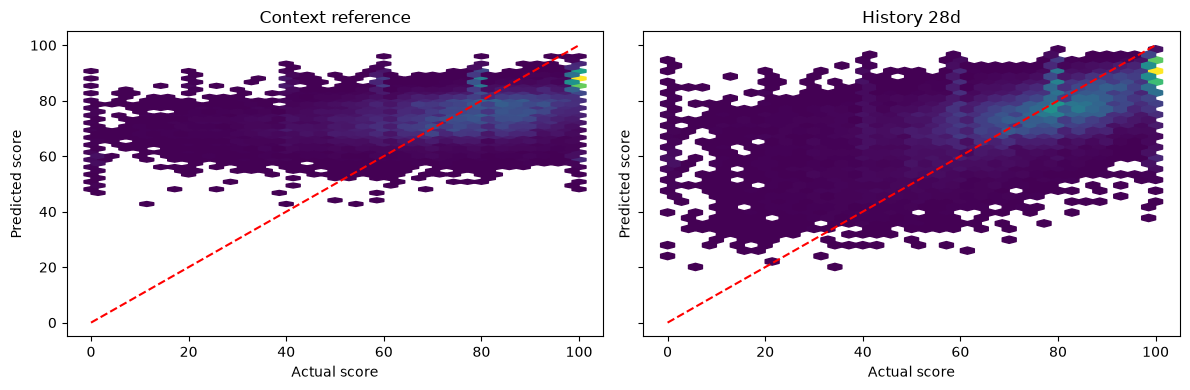

In [11]:
diagnostics = frame.loc[test_idx, ['id_student', 'code_module', 'assessment_type', 'score']].copy()
diagnostics['history_available'] = np.where(
    history_by_lag[PRIMARY_LAG].loc[test_idx, 'prior_count'].gt(0), 'Prior score available', 'No prior score')
diagnostics['score_band'] = pd.cut(diagnostics['score'], [-1, 39, 59, 79, 100],
    labels=['0-39', '40-59', '60-79', '80-100'])
diagnostics['context_prediction'] = predictions['Context reference']
diagnostics['history_prediction'] = predictions['History 28d']

for category in ['history_available', 'assessment_type', 'code_module', 'score_band']:
    rows = []
    for key, group in diagnostics.groupby(category, observed=True):
        context = metrics(group.score, group.context_prediction)
        history = metrics(group.score, group.history_prediction)
        rows.append({'category': key, 'assessments': len(group), 'students': group.id_student.nunique(),
            'Context RMSE': context['RMSE'], 'History RMSE': history['RMSE'],
            'Context MAE': context['MAE'], 'History MAE': history['MAE']})
    print(category)
    display(pd.DataFrame(rows).set_index('category'))

student_errors = diagnostics.assign(
    context_ae=abs(diagnostics.score - diagnostics.context_prediction),
    history_ae=abs(diagnostics.score - diagnostics.history_prediction)
).groupby('id_student')[['context_ae', 'history_ae']].mean().mean()
print('MAE with equal weight per test student:')
display(student_errors)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ['Context reference', 'History 28d']):
    ax.hexbin(y.loc[test_idx], predictions[name], gridsize=35, mincnt=1)
    ax.plot([0, 100], [0, 100], 'r--')
    ax.set(xlabel='Actual score', ylabel='Predicted score', title=name)
plt.tight_layout()
plt.show()


In [12]:
print('CONCLUSION')
for name in ['Context reference', 'History 28d', 'History 56d']:
    row = test_results.loc[name]
    print(f"{name}: R2={row['R2']:.3f}, RMSE={row['RMSE']:.3f}, MAE={row['MAE']:.3f}")
print(f'Predeclared robustness check: {notable_improvement}')
print('The context-only baseline is fitted and evaluated within this standalone notebook.')
print('No file is deleted, modified, or exported by this notebook.')
print('Grade-release timestamps are missing: results are conditional on the stated delay assumptions.')


CONCLUSION
Context reference: R2=0.160, RMSE=17.128, MAE=13.084
History 28d: R2=0.356, RMSE=14.991, MAE=10.999
History 56d: R2=0.305, RMSE=15.573, MAE=11.550
Predeclared robustness check: False
The context-only baseline is fitted and evaluated within this standalone notebook.
No file is deleted, modified, or exported by this notebook.
Grade-release timestamps are missing: results are conditional on the stated delay assumptions.


## Limits and reproduction

This experiment does not establish future-presentation performance or real grade-release
availability. Historical scores must come from actually released grades in an operational
system. Background attributes in studentInfo are treated as enrollment-time attributes;
there is no recorded version history to verify later edits. Only submitted, scored,
non-banked assessments with known deadlines are evaluated. Low-score errors and no-history
performance matter even if the overall comparison improves.

Both the context-only baseline and history-based model settings are defined above,
along with the complete student split and feature-building procedure.
All model choices use validation students; no test-driven parameter search or row filtering
is performed. Because the student holdout was previously inspected, reserve a genuinely
new student/course cohort for independent confirmation. Restart and run all cells in order
to reproduce. This notebook never writes Python files, CSV datasets, or model artifacts.
